# Customer, Product & Profitability Performance Analysis
**APL Logistics (KWE Group) | Supply Chain Commercial Intelligence**

**Objective:** find which customers, products, categories, markets and regions truly generate profit, and how discounting erodes margin.



**Margin definition used throughout:** `Profit / Order Item Total` (net of discount). This matches the dataset's own `Order Item Profit Ratio`. A gross version (`Profit / Sales`) is also reported in the KPI table.

## Importing Libraries and Data Loading

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", 50)



In [3]:
#importing data
df = pd.read_csv("C:/Users/Chandan/Desktop/Customer-Product-and-Profitability-Performance-Analysis/data/APL_Logistics.csv", encoding="latin-1")   # file is not UTF-8
print("Shape:", df.shape)
df.head()

Shape: (180519, 40)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,"78,521.00",3,Footwear,25.95,-97.51,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,"80,126.00",5,Golf,38.38,-104.73,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,"80,126.00",7,Fan Shop,38.38,-104.73,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,"80,126.00",7,Fan Shop,38.38,-104.73,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,"80,126.00",5,Golf,38.38,-104.73,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class


## 2. Data cleaning and financial validation

 Structure, nulls and duplicates

In [4]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Fname                 180519 non-null  object 
 12  Customer Id                   

In [5]:
nulls = df.isnull().sum()
print("\nColumns with nulls:\n", nulls[nulls > 0])


Columns with nulls:
 Customer Lname      8
Customer Zipcode    3
dtype: int64


###  Drop redundant and irrelevant columns
Four columns are exact copies of others (verified below), and several fields are personal or unused in a profitability analysis.

In [3]:
# Prove the duplicates are exact before dropping them
checks = {
    "Benefit per order == Order Profit Per Order": (df["Benefit per order"] - df["Order Profit Per Order"]).abs().max(),
    "Sales per customer == Order Item Total":      (df["Sales per customer"] - df["Order Item Total"]).abs().max(),
    "Product Price == Order Item Product Price":   (df["Product Price"] - df["Order Item Product Price"]).abs().max(),
    "Customer Id == Order Customer Id (mismatches)": (df["Customer Id"] != df["Order Customer Id"]).sum(),
}
for k, v in checks.items():
    print(f"{k}: max diff = {v}")

drop_cols = [
    "Benefit per order", "Sales per customer", "Product Price", "Order Customer Id",   # duplicates
    "Customer Fname", "Customer Lname", "Customer Street", "Customer Zipcode",         # personal / unused
]
df = df.drop(columns=drop_cols)
df["Customer Country"] = df["Customer Country"].replace({"EE. UU.": "USA"})
print("\nShape after dropping:", df.shape)

Benefit per order == Order Profit Per Order: max diff = 0.0
Sales per customer == Order Item Total: max diff = 0.0
Product Price == Order Item Product Price: max diff = 0.0
Customer Id == Order Customer Id (mismatches): max diff = 0

Shape after dropping: (180519, 32)


###  Financial validation

In [4]:
calc_sales = df["Order Item Product Price"] * df["Order Item Quantity"]
calc_total = df["Sales"] - df["Order Item Discount"]

print("Sales vs Price x Quantity, max abs diff:", (df["Sales"] - calc_sales).abs().max().round(4))
print("Order Item Total vs Sales - Discount, max abs diff:", (df["Order Item Total"] - calc_total).abs().max().round(4))

for c in ["Sales", "Order Item Quantity", "Order Item Product Price", "Order Item Total"]:
    print(f"Rows with {c} <= 0:", (df[c] <= 0).sum())

print("\nLoss-making orders (profit < 0):", (df["Order Profit Per Order"] < 0).sum())
print("Zero-profit orders:", (df["Order Profit Per Order"] == 0).sum())

# Which denominator does the provided profit ratio use?
gap_sales = (df["Order Profit Per Order"] / df["Sales"] - df["Order Item Profit Ratio"]).abs().max()
gap_total = (df["Order Profit Per Order"] / df["Order Item Total"] - df["Order Item Profit Ratio"]).abs().max()
print(f"\nProvided ratio vs Profit/Sales gap: {gap_sales:.4f}")
print(f"Provided ratio vs Profit/Order Item Total gap: {gap_total:.4f}  -> ratio is based on the net value")

Sales vs Price x Quantity, max abs diff: 0.0
Order Item Total vs Sales - Discount, max abs diff: 0.01
Rows with Sales <= 0: 0
Rows with Order Item Quantity <= 0: 0
Rows with Order Item Product Price <= 0: 0
Rows with Order Item Total <= 0: 0

Loss-making orders (profit < 0): 33784
Zero-profit orders: 1177

Provided ratio vs Profit/Sales gap: 0.6875
Provided ratio vs Profit/Order Item Total gap: 0.0055  -> ratio is based on the net value


**Findings:** all money fields reconcile and no zero or negative sales, quantity or price exist, so no rows need removal on validity grounds. Negative-profit rows are **kept** because they are the loss-making orders this project studies.

###  Order status decision
`CANCELED` and `SUSPECTED_FRAUD` orders do not represent realized revenue, yet they still carry positive profit, so they are excluded from profitability analysis. All other statuses are real orders and are retained.

In [5]:
print(df["Order Status"].value_counts())
EXCLUDE_STATUS = ["CANCELED", "SUSPECTED_FRAUD"]
removed = df["Order Status"].isin(EXCLUDE_STATUS).sum()
df = df[~df["Order Status"].isin(EXCLUDE_STATUS)].reset_index(drop=True)
print(f"\nRemoved {removed:,} rows ({removed/(removed+len(df)):.1%}). Remaining: {len(df):,}")

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64



Removed 7,754 rows (4.3%). Remaining: 172,765


## 3. Feature engineering

In [6]:
# Order identifier (one row = one order item in this dataset)
df["profit"] = df["Order Profit Per Order"]
df["margin_pct"] = df["profit"] / df["Order Item Total"] * 100          # net margin
df["gross_margin_pct"] = df["profit"] / df["Sales"] * 100               # on pre-discount sales

df["is_loss"] = (df["profit"] < 0).astype(int)
df["has_discount"] = (df["Order Item Discount"] > 0).astype(int)
df["discount_pct"] = df["Order Item Discount Rate"] * 100

bins = [-0.001, 0, 5, 10, 15, 20, 100]
labels = ["0%", "1-5%", "6-10%", "11-15%", "16-20%", "20%+"]
df["discount_band"] = pd.cut(df["discount_pct"].round(2), bins=bins, labels=labels)

df["shipping_delay"] = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
df["is_late"] = (df["shipping_delay"] > 0).astype(int)

df[["Sales", "Order Item Total", "profit", "margin_pct", "discount_pct", "discount_band", "is_loss"]].head()

,Sales,Order Item Total,profit,margin_pct,discount_pct,discount_band,is_loss
0,499.95,472.45,159.69,33.80,6.00,6-10%,0
1,199.95,167.96,48.71,29.00,16.00,16-20%,0
2,199.99,181.99,87.36,48.00,9.00,6-10%,0
3,199.99,175.99,-41.89,-23.80,12.00,11-15%,1
4,50.00,40.00,10.00,25.00,20.00,16-20%,0


In [7]:
print(df["discount_band"].value_counts().sort_index())
df["margin_pct"].describe()

discount_band
0%         9640
1-5%      48003
6-10%     38386
11-15%    28737
16-20%    38424
20%+       9575
Name: count, dtype: int64


count   172,765.00
mean         12.06
std          46.65
min        -275.08
25%           7.50
50%          27.00
75%          36.30
max          50.06
Name: margin_pct, dtype: float64

## 4. Revenue and profit overview

In [8]:
total_rev = df["Sales"].sum()
total_net = df["Order Item Total"].sum()
total_profit = df["profit"].sum()
total_disc = df["Order Item Discount"].sum()

overview = pd.Series({
    "Total Revenue (Sales)": total_rev,
    "Total Discounts": total_disc,
    "Net Revenue (Order Item Total)": total_net,
    "Total Profit": total_profit,
    "Profit Margin (net) %": total_profit / total_net * 100,
    "Profit Margin (gross) %": total_profit / total_rev * 100,
    "Loss-making orders": int(df["is_loss"].sum()),
    "Loss-making orders %": df["is_loss"].mean() * 100,
    "Total loss from loss-making orders": df.loc[df["profit"] < 0, "profit"].sum(),
})
overview.to_frame("Value")

,Value
Total Revenue (Sales),"35,214,428.98"
Total Discounts,"3,569,808.32"
Net Revenue (Order Item Total),"31,644,664.75"
Total Profit,"3,806,420.63"
Profit Margin (net) %,12.03
Profit Margin (gross) %,10.81
Loss-making orders,"32,295.00"
Loss-making orders %,18.69
Total loss from loss-making orders,"-3,708,393.18"


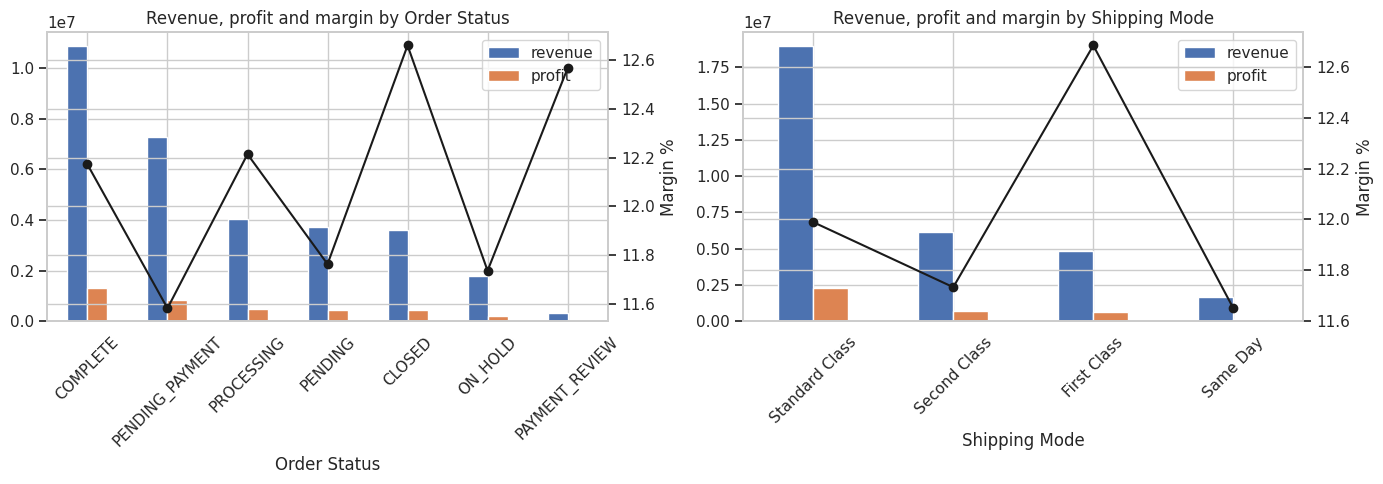

In [9]:
# No order date exists in the dataset, so compare revenue vs profit by order status and shipping mode instead of by month
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["Order Status", "Shipping Mode"]):
    g = df.groupby(col).agg(revenue=("Order Item Total", "sum"), profit=("profit", "sum"))
    g["margin"] = g.profit / g.revenue * 100
    g = g.sort_values("revenue", ascending=False)
    g[["revenue", "profit"]].plot(kind="bar", ax=ax)
    ax2 = ax.twinx(); ax2.plot(range(len(g)), g["margin"], "k-o"); ax2.set_ylabel("Margin %")
    ax.set_title(f"Revenue, profit and margin by {col}"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

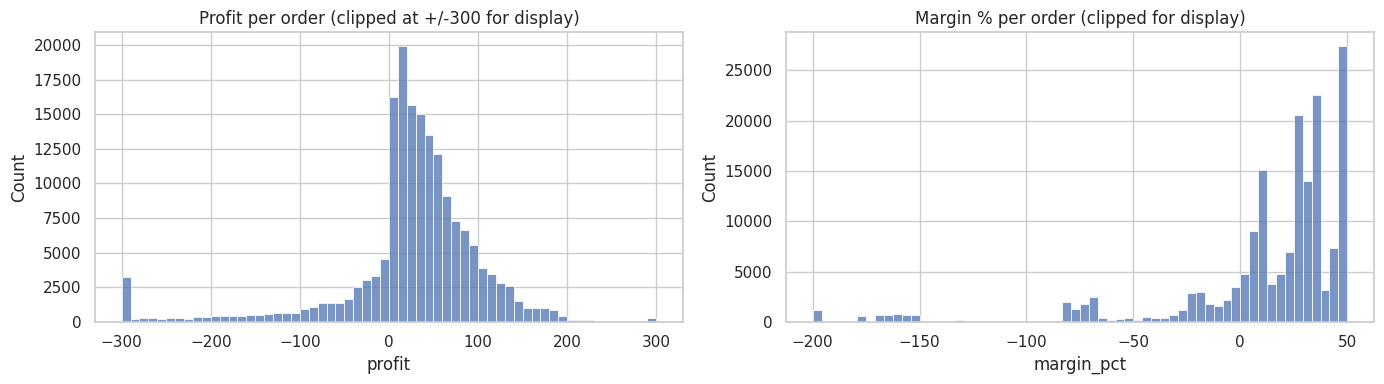

In [10]:
# Distribution of profit per order
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["profit"].clip(-300, 300), bins=60, ax=axes[0]); axes[0].set_title("Profit per order (clipped at +/-300 for display)")
sns.histplot(df["margin_pct"].clip(-200, 60), bins=60, ax=axes[1]); axes[1].set_title("Margin % per order (clipped for display)")
plt.tight_layout(); plt.show()

### Profit concentration (Pareto)

Customers: 6,362 of 20,261 (31.4%) generate 80% of positive profit
Products: 8 of 118 (6.8%) generate 80% of positive profit


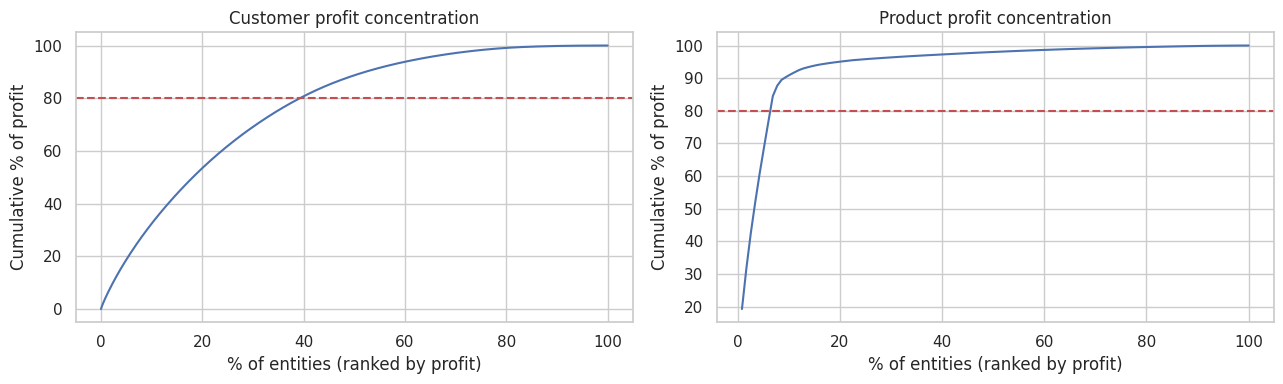

In [11]:
def pareto(series, name):
    s = series.sort_values(ascending=False)
    pos = s[s > 0]
    cum = pos.cumsum() / pos.sum()
    n80 = (cum <= 0.8).sum() + 1
    print(f"{name}: {n80:,} of {len(s):,} ({n80/len(s):.1%}) generate 80% of positive profit")
    return cum

cust_profit = df.groupby("Customer Id")["profit"].sum()
prod_profit = df.groupby("Product Name")["profit"].sum()
c1 = pareto(cust_profit, "Customers")
c2 = pareto(prod_profit, "Products")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(np.arange(1, len(c1)+1) / len(c1) * 100, c1.values * 100); axes[0].set_title("Customer profit concentration")
axes[1].plot(np.arange(1, len(c2)+1) / len(c2) * 100, c2.values * 100); axes[1].set_title("Product profit concentration")
for ax in axes:
    ax.axhline(80, ls="--", c="r"); ax.set_xlabel("% of entities (ranked by profit)"); ax.set_ylabel("Cumulative % of profit")
plt.tight_layout(); plt.show()

## 5. Product and category profitability

In [12]:
def profit_table(frame, by):
    g = frame.groupby(by).agg(
        revenue=("Order Item Total", "sum"),
        sales=("Sales", "sum"),
        profit=("profit", "sum"),
        orders=("profit", "size"),
        loss_orders=("is_loss", "sum"),
        avg_discount=("discount_pct", "mean"),
    )
    g["margin_pct"] = g.profit / g.revenue * 100
    g["loss_order_share_pct"] = g.loss_orders / g.orders * 100
    return g

cat = profit_table(df, "Category Name").sort_values("profit", ascending=False)
prod = profit_table(df, "Product Name").sort_values("profit", ascending=False)
print("Categories:", len(cat), "| Products:", len(prod))
print("Loss-making categories:", (cat.profit < 0).sum(), "| Loss-making products:", (prod.profit < 0).sum())
cat.head(10)

Categories: 50 | Products: 118
Loss-making categories: 0 | Loss-making products: 2


,revenue,sales,profit,orders,loss_orders,avg_discount,margin_pct,loss_order_share_pct
Category Name,,,,,,,,
Fishing,"5,964,765.28","6,637,668.10","731,576.18",16595,3047,10.17,12.26,18.36
Cleats,"3,815,653.36","4,244,593.89","474,629.51",23514,4389,10.14,12.44,18.67
Camping & Hiking,"3,546,428.19","3,946,836.86","409,895.62",13157,2486,10.17,11.56,18.89
Cardio Equipment,"3,174,909.18","3,533,289.21","362,984.70",11948,2237,10.16,11.43,18.72
Women's Apparel,"2,706,768.50","3,011,600.00","334,335.53",20116,3745,10.15,12.35,18.62
Water Sports,"2,679,256.70","2,981,851.20","308,981.34",14880,2799,10.17,11.53,18.81
Indoor/Outdoor Games,"2,485,575.60","2,765,543.34","302,403.77",18470,3471,10.15,12.17,18.79
Men's Footwear,"2,483,852.72","2,763,977.37","296,711.09",21263,3993,10.16,11.95,18.78
Shop By Sport,"1,126,786.15","1,253,395.61","125,077.03",10515,2061,10.14,11.10,19.60


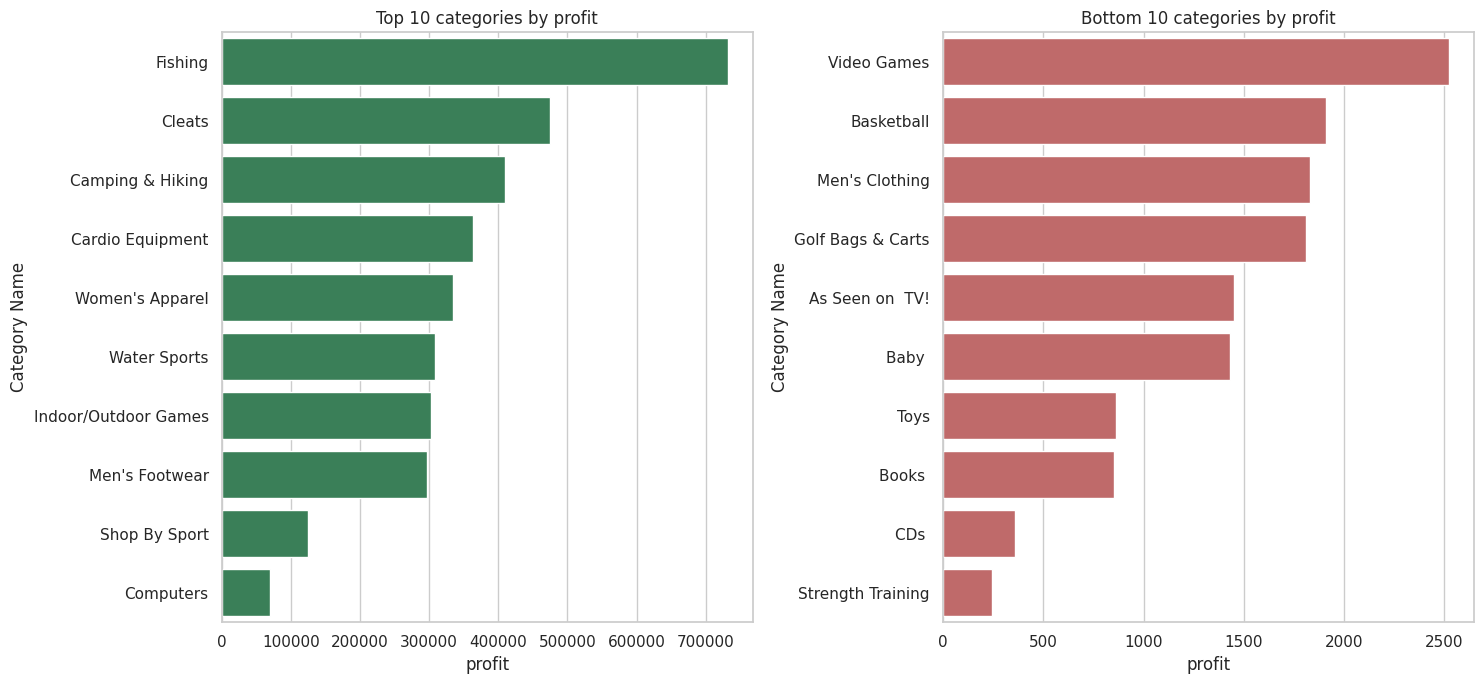

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
top = cat.head(10); bot = cat.tail(10)
sns.barplot(x=top.profit, y=top.index, ax=axes[0], color="seagreen"); axes[0].set_title("Top 10 categories by profit")
sns.barplot(x=bot.profit, y=bot.index, ax=axes[1], color="indianred"); axes[1].set_title("Bottom 10 categories by profit")
plt.tight_layout(); plt.show()

In [14]:
# High revenue but low margin: top quartile revenue, margin below median
hi_rev_low_margin = prod[(prod.revenue >= prod.revenue.quantile(0.75)) & (prod.margin_pct < prod.margin_pct.median())]
print(f"{len(hi_rev_low_margin)} high-revenue / low-margin products")
hi_rev_low_margin.sort_values("margin_pct")[["revenue", "profit", "margin_pct", "avg_discount", "loss_order_share_pct"]].head(15)

16 high-revenue / low-margin products


,revenue,profit,margin_pct,avg_discount,loss_order_share_pct
Product Name,,,,,
Men's gala suit,"37,456.46","1,829.20",4.88,10.31,24.24
Titleist Pro V1x Golf Balls,"36,687.89","3,493.84",9.52,9.93,18.79
Adult dog supplies,"35,834.98","3,505.18",9.78,10.07,20.55
First aid kit,"91,249.68","9,281.12",10.17,10.03,23.41
Under Armour Women's Micro G Skulpt Running S,"39,734.44","4,084.07",10.28,10.16,18.01
DVDs,"67,783.61","7,168.83",10.58,10.19,20.26
Under Armour Girls' Toddler Spine Surge Runni,"1,092,050.64","121,834.27",11.16,10.15,19.62
Smart watch,"99,131.33","11,240.76",11.34,10.01,16.96
Nike Men's Free 5.0+ Running Shoe,"3,151,671.18","359,793.63",11.42,10.16,18.74


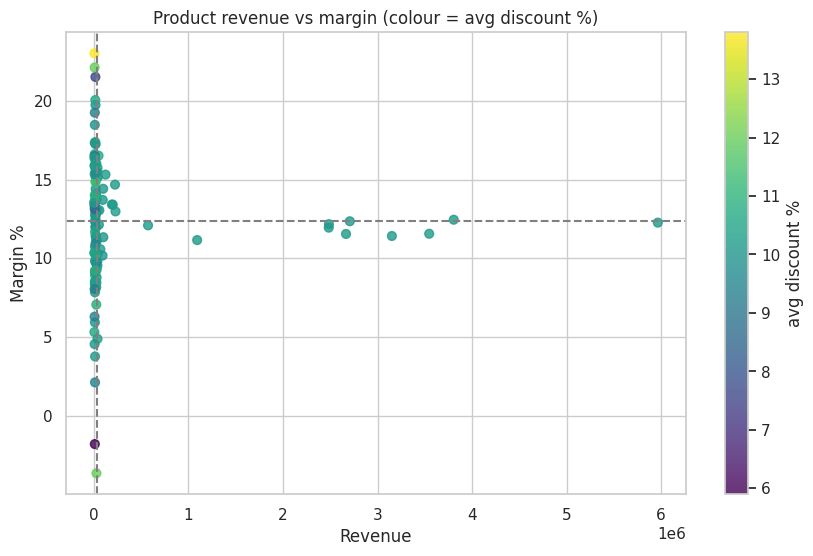

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(prod.revenue, prod.margin_pct, s=40, c=prod.avg_discount, cmap="viridis", alpha=0.8)
ax.axhline(prod.margin_pct.median(), ls="--", c="grey"); ax.axvline(prod.revenue.quantile(0.75), ls="--", c="grey")
ax.set_xlabel("Revenue"); ax.set_ylabel("Margin %"); ax.set_title("Product revenue vs margin (colour = avg discount %)")
plt.colorbar(sc, label="avg discount %"); plt.show()

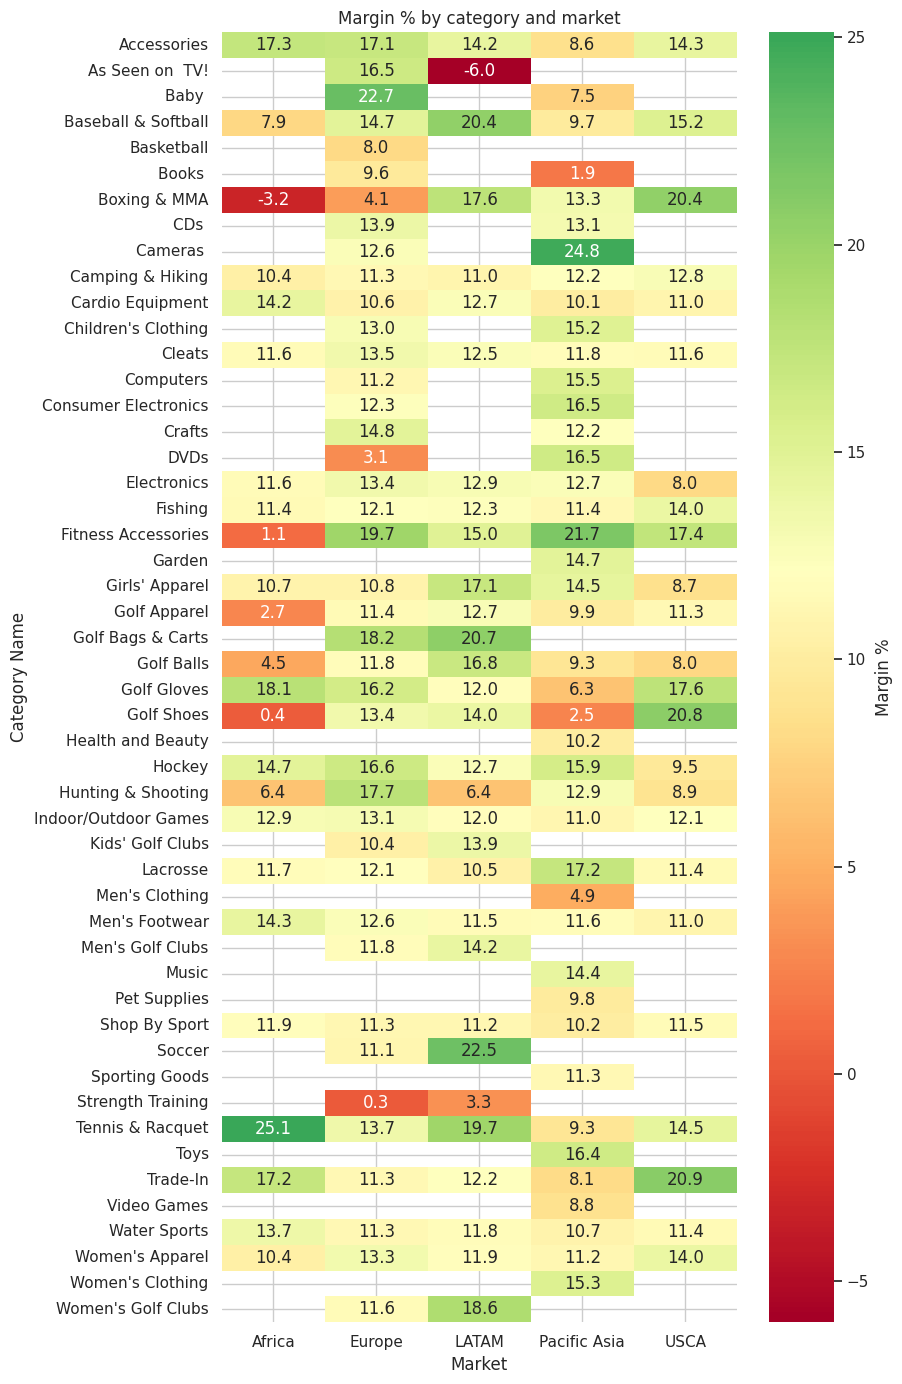

In [16]:
# Category x Market margin heatmap
pivot_p = df.pivot_table(index="Category Name", columns="Market", values="profit", aggfunc="sum")
pivot_r = df.pivot_table(index="Category Name", columns="Market", values="Order Item Total", aggfunc="sum")
heat = (pivot_p / pivot_r * 100)
plt.figure(figsize=(9, 14))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdYlGn", center=heat.stack().median(), cbar_kws={"label": "Margin %"})
plt.title("Margin % by category and market"); plt.tight_layout(); plt.show()

## 6. Customer contribution analysis

In [17]:
cust = df.groupby("Customer Id").agg(
    segment=("Customer Segment", "first"),
    revenue=("Order Item Total", "sum"),
    sales=("Sales", "sum"),
    profit=("profit", "sum"),
    orders=("profit", "size"),
    loss_orders=("is_loss", "sum"),
    avg_discount=("discount_pct", "mean"),
)
cust["margin_pct"] = cust.profit / cust.revenue * 100
cust["customer_value_index"] = cust.profit / cust.profit.mean()      # 1.0 = average customer

cust["tier"] = pd.qcut(cust.profit.rank(method="first"), 4, labels=["Low", "Medium", "High", "Platinum"])
print("Customers:", len(cust))
print("Loss-making customers:", (cust.profit < 0).sum(), f"({(cust.profit < 0).mean():.1%})")
cust.sort_values("profit", ascending=False).head(10)

Customers: 20261
Loss-making customers: 4001 (19.7%)


,segment,revenue,sales,profit,orders,loss_orders,avg_discount,margin_pct,customer_value_index,tier
Customer Id,,,,,,,,,,
2641,Consumer,"8,221.64","9,130.92","2,441.97",43,5,9.49,29.70,13.00,Platinum
1657,Consumer,"8,165.23","9,223.71","2,196.92",42,4,11.48,26.91,11.69,Platinum
9833,Consumer,"5,386.46","6,059.38","1,938.39",24,1,11.08,35.99,10.32,Platinum
2626,Consumer,"5,477.84","6,274.36","1,928.57",27,0,12.11,35.21,10.27,Platinum
5004,Home Office,"7,499.37","8,164.70","1,917.99",45,7,8.87,25.58,10.21,Platinum
3735,Corporate,"5,532.41","6,019.33","1,906.36",27,2,8.04,34.46,10.15,Platinum
5560,Corporate,"6,118.59","6,528.21","1,831.46",29,1,7.34,29.93,9.75,Platinum
10967,Consumer,"5,181.65","5,734.41","1,822.33",27,0,9.00,35.17,9.70,Platinum
2224,Corporate,"6,200.46","6,774.46","1,799.87",31,2,9.42,29.03,9.58,Platinum


In [18]:
cust.sort_values("profit").head(10)

,segment,revenue,sales,profit,orders,loss_orders,avg_discount,margin_pct,customer_value_index,tier
Customer Id,,,,,,,,,,
1428,Consumer,"3,631.04","3,883.67","-3,868.56",13,2,9.00,-106.54,-20.59,Low
14086,Home Office,"1,350.00","1,500.00","-3,442.50",1,1,10.00,-255.00,-18.32,Low
18109,Corporate,"1,320.00","1,500.00","-3,366.00",1,1,12.00,-255.00,-17.92,Low
14313,Consumer,"1,200.00","1,500.00","-3,000.00",1,1,20.00,-250.00,-15.97,Low
18061,Consumer,"1,440.00","1,500.00","-2,592.00",1,1,4.00,-180.00,-13.80,Low
14113,Consumer,"1,500.00","1,500.00","-2,550.00",1,1,0.00,-170.00,-13.57,Low
14090,Corporate,"1,425.00","1,500.00","-2,351.25",1,1,5.00,-165.00,-12.52,Low
14398,Home Office,"1,455.00","1,500.00","-2,328.00",1,1,3.00,-160.00,-12.39,Low
14306,Home Office,"1,425.00","1,500.00","-2,280.00",1,1,5.00,-160.00,-12.14,Low


In [19]:
tier = cust.groupby("tier").agg(
    customers=("profit", "size"), revenue=("revenue", "sum"), profit=("profit", "sum"),
    avg_margin=("margin_pct", "mean"), avg_orders=("orders", "mean"), avg_discount=("avg_discount", "mean"))
tier["profit_share_pct"] = tier.profit / tier.profit.sum() * 100
tier["revenue_share_pct"] = tier.revenue / tier.revenue.sum() * 100
tier

,customers,revenue,profit,avg_margin,avg_orders,avg_discount,profit_share_pct,revenue_share_pct
tier,,,,,,,,
Low,5066,"6,286,266.16","-1,047,652.87",-22.54,6.96,10.24,-27.52,19.87
Medium,5065,"2,556,921.65","248,883.23",23.52,2.81,10.41,6.54,8.08
High,5065,"7,711,898.32","1,166,564.84",23.02,8.27,9.95,30.65,24.37
Platinum,5065,"15,089,578.62","3,438,625.43",24.57,16.07,10.06,90.34,47.68


In [20]:
# High sales but weak profit: top-quartile revenue, bottom-quartile margin
risky = cust[(cust.revenue >= cust.revenue.quantile(0.75)) & (cust.margin_pct <= cust.margin_pct.quantile(0.25))]
print(f"{len(risky)} customers are high-revenue but bottom-quartile margin")
risky.sort_values("revenue", ascending=False).head(10)[["segment", "revenue", "profit", "margin_pct", "avg_discount"]]

1323 customers are high-revenue but bottom-quartile margin


,segment,revenue,profit,margin_pct,avg_discount
Customer Id,,,,,
791,Corporate,"9,436.61",-866.38,-9.18,9.51
5715,Corporate,"7,881.10",-177.45,-2.25,9.30
664,Home Office,"7,549.04",-68.45,-0.91,9.54
1288,Home Office,"7,234.06",276.78,3.83,10.74
1011,Corporate,"7,229.80",10.89,0.15,9.58
9727,Home Office,"6,945.64",116.24,1.67,12.46
6375,Corporate,"6,917.33",-40.92,-0.59,11.47
9300,Home Office,"6,881.15",-278.47,-4.05,9.00
7631,Corporate,"6,665.40",-234.52,-3.52,9.65


,customers,revenue,profit,margin_pct,profit_share_pct,profit_per_customer,loss_order_share_pct
Customer Segment,,,,,,,
Consumer,10487,"16,417,549.44","1,982,863.62",12.08,52.09,189.08,18.61
Corporate,6120,"9,621,051.58","1,157,821.04",12.03,30.42,189.19,18.81
Home Office,3654,"5,606,063.73","665,735.97",11.88,17.49,182.19,18.76


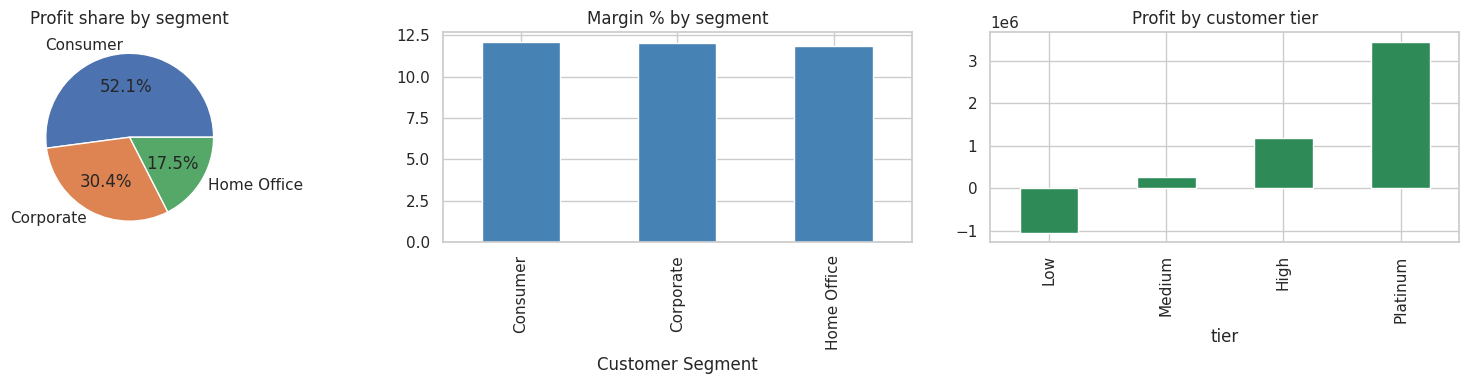

In [21]:
seg = profit_table(df, "Customer Segment")
seg["customers"] = df.groupby("Customer Segment")["Customer Id"].nunique()
seg["profit_per_customer"] = seg.profit / seg.customers
seg["profit_share_pct"] = seg.profit / seg.profit.sum() * 100
display(seg[["customers", "revenue", "profit", "margin_pct", "profit_share_pct", "profit_per_customer", "loss_order_share_pct"]])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
seg.profit.plot(kind="pie", autopct="%1.1f%%", ax=axes[0], ylabel=""); axes[0].set_title("Profit share by segment")
seg.margin_pct.plot(kind="bar", ax=axes[1], color="steelblue"); axes[1].set_title("Margin % by segment")
cust.groupby("tier").profit.sum().plot(kind="bar", ax=axes[2], color="seagreen"); axes[2].set_title("Profit by customer tier")
plt.tight_layout(); plt.show()

## 7. Discount impact diagnostics

In [22]:
# With vs without discount
wd = df.groupby("has_discount").agg(
    orders=("profit", "size"), revenue=("Order Item Total", "sum"), profit=("profit", "sum"),
    avg_profit_per_order=("profit", "mean"), loss_share=("is_loss", "mean"))
wd["margin_pct"] = wd.profit / wd.revenue * 100
wd.index = ["No discount", "Discounted"]
wd

,orders,revenue,profit,avg_profit_per_order,loss_share,margin_pct
No discount,9640,"1,966,128.04","254,642.79",26.42,0.19,12.95
Discounted,163125,"29,678,536.71","3,551,777.84",21.77,0.19,11.97


In [23]:
band = df.groupby("discount_band").agg(
    orders=("profit", "size"), revenue=("Order Item Total", "sum"), profit=("profit", "sum"),
    avg_profit=("profit", "mean"), loss_share=("is_loss", "mean"), avg_ratio=("Order Item Profit Ratio", "mean"))
band["margin_pct"] = band.profit / band.revenue * 100
band["loss_share"] *= 100
band

,orders,revenue,profit,avg_profit,loss_share,avg_ratio,margin_pct
discount_band,,,,,,,
0%,9640,"1,966,128.04","254,642.79",26.42,18.57,0.13,12.95
1-5%,48003,"9,482,703.92","1,125,743.14",23.45,18.67,0.12,11.87
6-10%,38386,"7,212,039.88","882,469.98",22.99,18.35,0.12,12.24
11-15%,28737,"5,074,819.31","599,919.36",20.88,18.95,0.12,11.82
16-20%,38424,"6,444,632.78","755,546.32",19.66,19.01,0.12,11.72
20%+,9575,"1,464,340.82","188,099.04",19.64,18.26,0.13,12.85


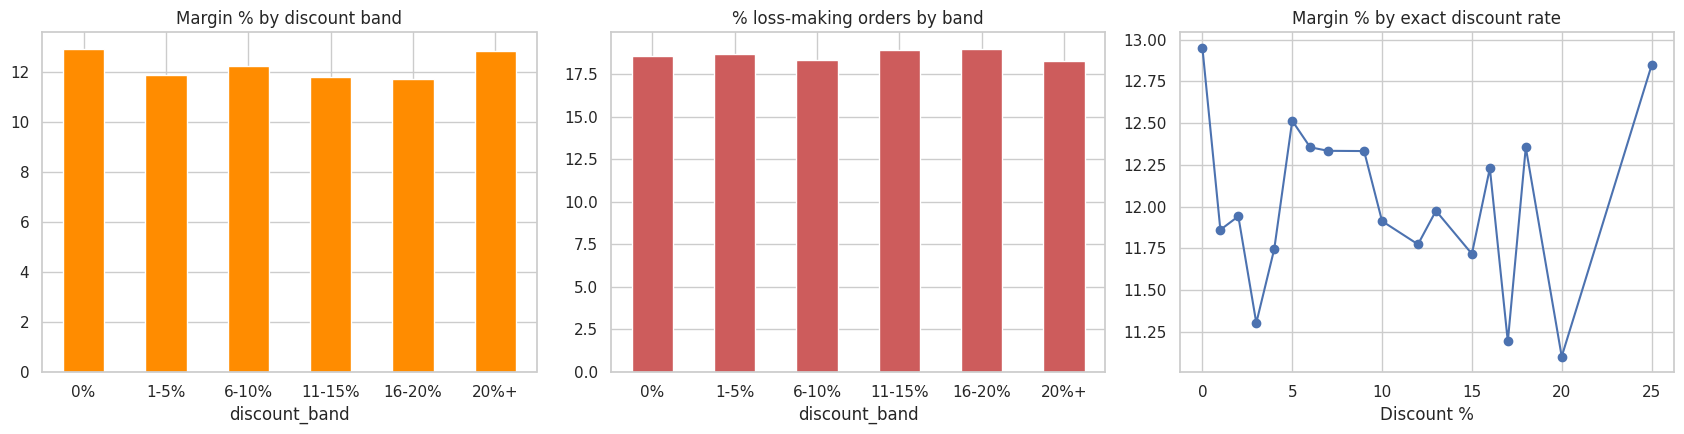

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
band.margin_pct.plot(kind="bar", ax=axes[0], color="darkorange"); axes[0].set_title("Margin % by discount band"); axes[0].tick_params(axis="x", rotation=0)
band.loss_share.plot(kind="bar", ax=axes[1], color="indianred"); axes[1].set_title("% loss-making orders by band"); axes[1].tick_params(axis="x", rotation=0)

# Discount rate step by step (rates move in 1-point steps)
rate = df.assign(rate=df.discount_pct.round()).groupby("rate").agg(
    profit=("profit", "sum"), revenue=("Order Item Total", "sum"))
rate["margin_pct"] = rate.profit / rate.revenue * 100
axes[2].plot(rate.index, rate.margin_pct, "-o"); axes[2].set_title("Margin % by exact discount rate"); axes[2].set_xlabel("Discount %")
plt.tight_layout(); plt.show()

In [25]:
# Statistical tests
rho, p_rho = stats.spearmanr(df["Order Item Discount Rate"], df["Order Item Profit Ratio"])
print(f"Spearman (discount rate vs profit ratio): rho = {rho:.4f}, p = {p_rho:.3g}")

a = df.loc[df.has_discount == 0, "Order Item Profit Ratio"]
b = df.loc[df.has_discount == 1, "Order Item Profit Ratio"]
t, p_t = stats.ttest_ind(a, b, equal_var=False)
print(f"Welch t-test (no discount vs discounted): t = {t:.3f}, p = {p_t:.3g}")
print(f"Mean profit ratio: no discount = {a.mean():.4f}, discounted = {b.mean():.4f}")

# Kruskal-Wallis across bands (non-parametric, distributions are skewed)
groups = [g["Order Item Profit Ratio"].values for _, g in df.groupby("discount_band")]
h, p_h = stats.kruskal(*groups)
print(f"Kruskal-Wallis across discount bands: H = {h:.2f}, p = {p_h:.3g}")

Spearman (discount rate vs profit ratio): rho = -0.0016, p = 0.513
Welch t-test (no discount vs discounted): t = 1.018, p = 0.309
Mean profit ratio: no discount = 0.1254, discounted = 0.1205
Kruskal-Wallis across discount bands: H = 10.75, p = 0.0565


**How to read these results:** in this dataset the discount rate has almost no statistical relationship with the profit ratio (Spearman rho is about 0, and the with vs without discount t-test is not significant). Margin stays around 12% in every band, including 20%+. So the data does **not** show a discount threshold where margin collapses. Report that honestly rather than forcing the brief's hypothesis. The Discount Impact Ratio below is small (about 7.6%) and the band-to-band differences are not statistically meaningful, so treat the ratio as descriptive only.

In [26]:
# Discount Impact Ratio = (margin at 0% discount - margin on discounted orders) / margin at 0% discount
m0 = wd.loc["No discount", "margin_pct"]
m1 = wd.loc["Discounted", "margin_pct"]
DIR = (m0 - m1) / m0
print(f"Margin without discount: {m0:.2f}% | with discount: {m1:.2f}% | Discount Impact Ratio: {DIR:.2%}")

# Same ratio per band
band["discount_impact_ratio"] = (m0 - band.margin_pct) / m0
band[["margin_pct", "discount_impact_ratio"]]

Margin without discount: 12.95% | with discount: 11.97% | Discount Impact Ratio: 7.60%


,margin_pct,discount_impact_ratio
discount_band,,
0%,12.95,0.00
1-5%,11.87,0.08
6-10%,12.24,0.06
11-15%,11.82,0.09
16-20%,11.72,0.09
20%+,12.85,0.01


In [27]:
# Threshold finder: first band where margin falls below a chosen floor
FLOOR = 10   # business floor for margin %, change as needed
below = band[band.margin_pct < FLOOR]
print("Margin by band:\n", band.margin_pct.round(2).to_string())
print(f"\nFirst band below {FLOOR}% margin:", below.index[0] if len(below) else "none")

Margin by band:
 discount_band
0%       12.95
1-5%     11.87
6-10%    12.24
11-15%   11.82
16-20%   11.72
20%+     12.85

First band below 10% margin: none


In [28]:
# What-if: cap the discount rate and recompute profit (assumes volume does not change)
def whatif_cap(frame, cap_pct):
    capped_rate = np.minimum(frame["Order Item Discount Rate"], cap_pct / 100)
    new_discount = capped_rate * frame["Sales"]
    extra_revenue = frame["Order Item Discount"] - new_discount        # discount saved
    new_profit = frame["profit"] + extra_revenue
    new_net = frame["Order Item Total"] + extra_revenue
    return new_profit.sum(), new_profit.sum() / new_net.sum() * 100

base_p, base_m = df.profit.sum(), df.profit.sum() / df["Order Item Total"].sum() * 100
rows = [("Current", base_p, base_m)]
for cap in [20, 15, 10, 5, 0]:
    p, m = whatif_cap(df, cap); rows.append((f"Cap at {cap}%", p, m))
sc = pd.DataFrame(rows, columns=["Scenario", "Profit", "Margin %"]).set_index("Scenario")
sc["Profit change %"] = (sc.Profit / base_p - 1) * 100
sc

,Profit,Margin %,Profit change %
Scenario,,,
Current,"3,806,420.63",12.03,0.00
Cap at 20%,"3,894,418.68",12.27,2.31
Cap at 15%,"4,207,635.69",13.13,10.54
Cap at 10%,"4,892,345.19",14.95,28.53
Cap at 5%,"5,909,366.35",17.51,55.25
Cap at 0%,"7,376,228.95",20.95,93.78


*What-if caveat: the calculation assumes every dollar of discount removed becomes profit and that customers buy the same volume. That is a mechanical upper bound, not a forecast. The larger caps (especially 0%) are unrealistic because demand would fall. Since the data shows no link between discount rate and profit ratio, the observed margins give no evidence that discounts bought extra profitable volume or destroyed it. Use the 15-20% caps as the plausible range and state the assumption in your paper.*

## 8. Market and regional profit analysis

In [29]:
market = profit_table(df, "Market").sort_values("profit", ascending=False)
market["revenue_share_pct"] = market.revenue / market.revenue.sum() * 100
market["profit_share_pct"] = market.profit / market.profit.sum() * 100
market

,revenue,sales,profit,orders,loss_orders,avg_discount,margin_pct,loss_order_share_pct,revenue_share_pct,profit_share_pct
Market,,,,,,,,,,
Europe,"9,348,369.23","10,405,371.25","1,131,937.91",48090,8967,10.18,12.11,18.65,29.54,29.74
LATAM,"8,829,847.07","9,824,329.57","1,069,050.79",49309,9176,10.14,12.11,18.61,27.90,28.09
Pacific Asia,"7,137,290.21","7,942,351.67","826,167.16",39585,7485,10.17,11.58,18.91,22.55,21.70
USCA,"4,346,978.39","4,836,413.48","539,223.29",24627,4593,10.15,12.40,18.65,13.74,14.17
Africa,"1,982,179.85","2,205,963.01","240,041.48",11154,2074,10.15,12.11,18.59,6.26,6.31


In [30]:
region = profit_table(df, "Order Region").sort_values("profit", ascending=False)
region["revenue_share_pct"] = region.revenue / region.revenue.sum() * 100
region["profit_share_pct"] = region.profit / region.profit.sum() * 100
region[["revenue", "profit", "margin_pct", "revenue_share_pct", "profit_share_pct", "loss_order_share_pct"]]

,revenue,profit,margin_pct,revenue_share_pct,profit_share_pct,loss_order_share_pct
Order Region,,,,,,
Western Europe,"5,056,355.16","607,319.63",12.01,15.98,15.96,18.71
Central America,"4,884,996.00","586,567.12",12.01,15.44,15.41,18.62
South America,"2,528,275.09","315,501.98",12.48,7.99,8.29,18.50
Northern Europe,"1,864,435.57","226,419.40",12.14,5.89,5.95,18.48
Southern Europe,"1,755,487.56","221,344.17",12.61,5.55,5.82,18.21
Southeast Asia,"1,665,459.90","202,242.88",12.14,5.26,5.31,18.87
Oceania,"1,736,607.76","195,381.26",11.25,5.49,5.13,19.03
Caribbean,"1,416,575.98","166,981.69",11.79,4.48,4.39,18.75
West of USA,"1,339,329.51","159,186.83",11.89,4.23,4.18,18.76


In [31]:
country = profit_table(df, "Order Country")
country = country[country.orders >= 100]       # ignore tiny samples
print("Countries with >= 100 orders:", len(country))
display(country.sort_values("margin_pct").head(10)[["revenue", "profit", "margin_pct", "orders"]])
display(country.sort_values("margin_pct", ascending=False).head(10)[["revenue", "profit", "margin_pct", "orders"]])

Countries with >= 100 orders: 96


,revenue,profit,margin_pct,orders
Order Country,,,,
Angola,"49,899.28",257.06,0.52,297
Afganistán,"33,216.37",483.80,1.46,155
Jordania,"17,138.96",937.34,5.47,105
Irlanda,"100,521.57","5,667.79",5.64,468
Mali,"17,808.97","1,053.95",5.92,103
Ecuador,"50,360.67","3,219.48",6.39,279
Togo,"20,945.85","1,552.19",7.41,120
Kenia,"44,317.32","3,466.27",7.82,229
Zambia,"48,662.41","3,811.63",7.83,259


,revenue,profit,margin_pct,orders
Order Country,,,,
Mozambique,"42,225.10","8,464.16",20.05,238
Camerún,"44,585.28","7,916.30",17.76,256
Trinidad y Tobago,"23,015.65","3,955.33",17.19,126
Hungría,"31,593.04","5,387.73",17.05,175
Níger,"20,828.33","3,525.03",16.92,105
Libia,"18,621.83","3,125.55",16.78,102
Jamaica,"28,652.59","4,649.74",16.23,162
Portugal,"63,141.86","10,024.22",15.88,317
Venezuela,"164,955.04","26,045.04",15.79,921


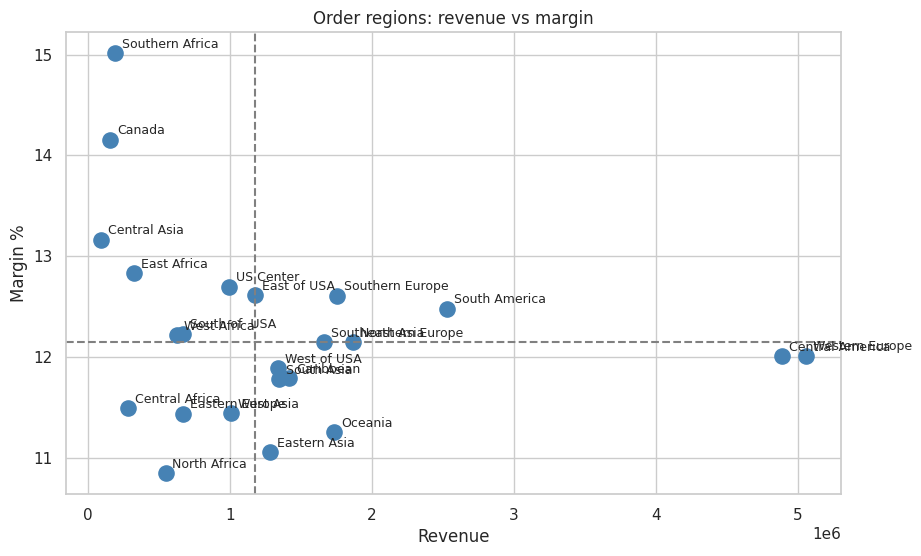

In [32]:
# Strong revenue, weak profit: revenue vs margin quadrant for regions
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(region.revenue, region.margin_pct, s=120, c="steelblue")
for name, r in region.iterrows():
    ax.annotate(name, (r.revenue, r.margin_pct), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(region.margin_pct.median(), ls="--", c="grey"); ax.axvline(region.revenue.median(), ls="--", c="grey")
ax.set_xlabel("Revenue"); ax.set_ylabel("Margin %"); ax.set_title("Order regions: revenue vs margin")
plt.show()

In [33]:
# Does the margin gap between markets come from discounting or from product mix?
mix = df.groupby("Market").agg(avg_discount=("discount_pct", "mean"), loss_share=("is_loss", "mean"), late_share=("is_late", "mean"))
mix["margin_pct"] = market.margin_pct
mix

,avg_discount,loss_share,late_share,margin_pct
Market,,,,
Africa,10.15,0.19,0.57,12.11
Europe,10.18,0.19,0.58,12.11
LATAM,10.14,0.19,0.57,12.11
Pacific Asia,10.17,0.19,0.57,11.58
USCA,10.15,0.19,0.57,12.40


## 9. KPI summary

In [34]:
kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue (Sales)", "Net Revenue", "Total Profit",
        "Profit Margin % (net, on Order Item Total)", "Profit Margin % (gross, on Sales)",
        "Customer Value Index (top customer)", "Avg profit per customer",
        "Best category margin %", "Worst category margin %",
        "Discount Impact Ratio", "Loss-making orders %", "Loss-making customers %",
    ],
    "Value": [
        total_rev, total_net, total_profit,
        total_profit / total_net * 100, total_profit / total_rev * 100,
        cust.customer_value_index.max(), cust.profit.mean(),
        cat.margin_pct.max(), cat.margin_pct.min(),
        DIR * 100, df.is_loss.mean() * 100, (cust.profit < 0).mean() * 100,
    ],
})
kpis

,KPI,Value
0,Total Revenue (Sales),"35,214,428.98"
1,Net Revenue,"31,644,664.75"
2,Total Profit,"3,806,420.63"
3,"Profit Margin % (net, on Order Item Total)",12.03
4,"Profit Margin % (gross, on Sales)",10.81
5,Customer Value Index (top customer),13.00
6,Avg profit per customer,187.87
7,Best category margin %,19.25
8,Worst category margin %,0.50
9,Discount Impact Ratio,7.60


## 10. Key findings (fill in after reviewing your outputs)
- **Profit concentration:** ...
- **Loss-making categories / products:** ...
- **Customer tiers:** ...
- **Discount threshold where margin erodes:** ...
- **Markets with strong revenue but weak profit:** ...
- **Recommendations:** ...

## 11. Export for the Streamlit app

In [35]:
clean_cols = [
    "Type", "Days for shipping (real)", "Days for shipment (scheduled)", "Delivery Status", "Late_delivery_risk",
    "Category Id", "Category Name", "Customer City", "Customer Country", "Customer Id", "Customer Segment", "Customer State",
    "Department Name", "Market", "Order City", "Order Country", "Order Region", "Order State", "Order Status",
    "Product Name", "Shipping Mode", "Order Item Discount", "Order Item Discount Rate", "Order Item Product Price",
    "Order Item Profit Ratio", "Order Item Quantity", "Sales", "Order Item Total", "Order Profit Per Order",
    "profit", "margin_pct", "gross_margin_pct", "is_loss", "has_discount", "discount_pct", "discount_band",
    "shipping_delay", "is_late",
]
df[clean_cols].to_csv("clean_data.csv", index=False)
cust.reset_index().to_csv("customer_summary.csv", index=False)
prod.reset_index().to_csv("product_summary.csv", index=False)
print("Saved clean_data.csv, customer_summary.csv, product_summary.csv")
print("Final shape:", df[clean_cols].shape)

Saved clean_data.csv, customer_summary.csv, product_summary.csv
Final shape: (172765, 38)
